## A. Data Understanding

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

columns = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']
columns_of_interest = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'Full audio languages', 'Reviews', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'User score', 'Positive', 'Negative', 'Score rank', 'Recommendations', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags']

In [35]:
df = pd.read_csv("games.csv",names=columns, on_bad_lines="skip", usecols=columns_of_interest,header=0)

In [36]:
# with open("games.csv", "r", encoding="utf-8") as f:
#     print(f.readline())

In [37]:
df.shape

(125855, 28)

## The first goal we have is to find whether the number of games a developer releases is positevely correlated the developer's success. To o so, we look at the count of games released under the same developer, and the game engagement, which will be measured by positive votes in the "Positive" column

([<matplotlib.axis.XTick at 0x7b967e374f50>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20'),
  Text(21, 0, '21'),
  Text(22, 0, '22'),
  Text(23, 0, '23'),
  Text(24, 0, '24'),
  Text(25, 0, '25'),
  Text(26, 0, '26'),
  Text(27, 0, '27'),
  Text(28, 0, '28'),
  Text(29, 0, '29'),
  Text(30, 0, '30'),
  Text(31, 0, '31'),
  Text(32, 0, '32'),
  Text(33, 0, '33'),
  Text(34, 0, '34'),
  Text(35, 0, '35'),
  Text(36, 0, '36'),
  Text(37, 0, '37'),
  Text(38, 0, '38'),
  Text(39, 0, '39'),
  Text(40, 0, '40'),
  Text(41, 0, '41'),
  Text(42, 0, '42'),
  Text(43, 0, '43'),
  Text(44, 0, '44'),
  Text(45, 0, '45'),
  Text(46, 0, '46'),
  Text(

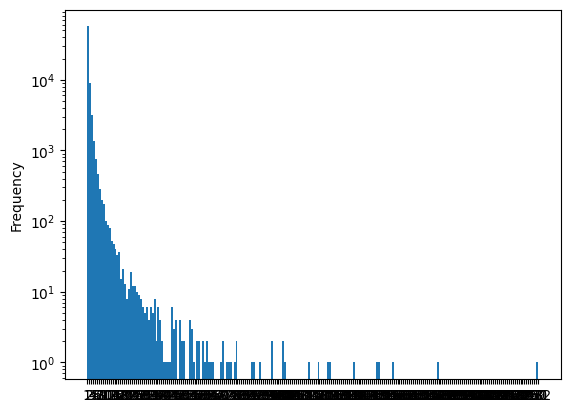

In [38]:
result = df.groupby("Developers").agg(
    positive=("Positive", "sum"),
    count=("Developers", "size")
)
maxX = round(result["count"].max())
result["count"].plot.hist(bins=range(1,maxX+1))
plt.yscale("log")
plt.xticks(range(1,maxX+1))

This first histogram shows the number of developers as a function of games released by the developer. We can see a high number of developers that have only published one game, and a steep decline in number of published games, with few outliers


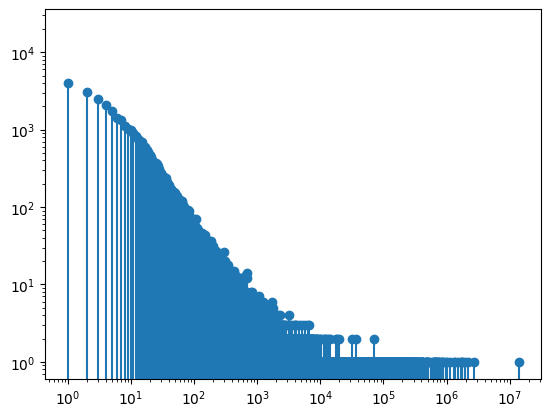

In [39]:
freq = result['positive'].value_counts().sort_index()

plt.stem(freq.index, freq.values)
plt.yscale("log")
plt.xscale("log")

Now, we can see the number of developers to reach certain thresholds of engagement; in the x axis, we have the count of 'positive' votes, while in the y-axis, we have the number of developers. As expected, a great majority of developers sees sall engagement with their games, with a high density of them seeing medium engagement, and a few met with high engagement counts

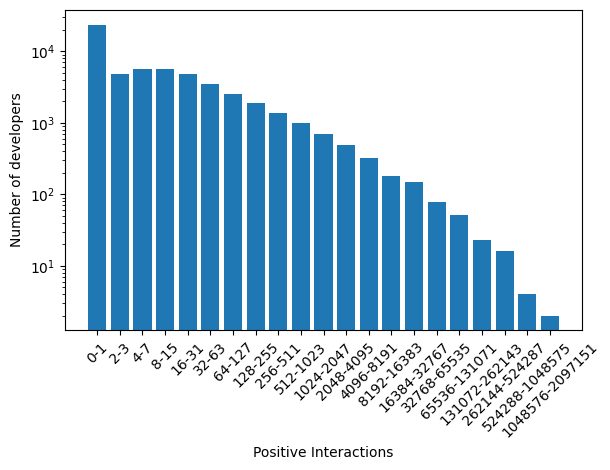

In [40]:
dev_game_one = result[result["count"] == 1]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_one["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_one["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.yscale("log")
plt.show()

Transforming the scales of our graph, we now look exclusively at developers who released a single game, and the number of interactions that game received. We can observa peak of engagement between 4 to 15, slowly declining after

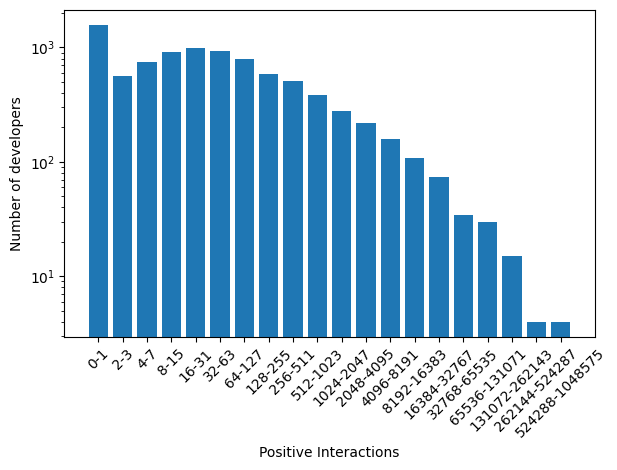

In [41]:
dev_game_two = result[result["count"] == 2]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_two["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_two["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.yscale("log")
plt.show()

When looking at developers who released 2 games, we can notice the peak engagement shift updward, now sitting around the 16-31 range.

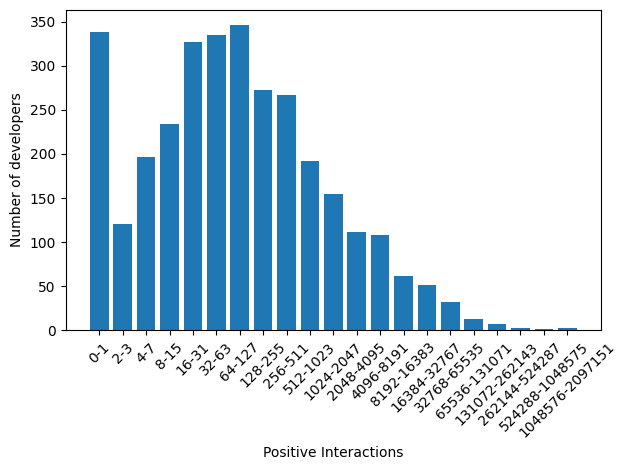

In [42]:
dev_game_three = result[result["count"] == 3]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_three["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_three["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
# plt.yscale("log")
plt.show()

When looking at developers with 3 games released, there is a clear peak density at the64-127 engagement range, indicating an upward trend. But more interestingly, the peak is higher than the number of developers with 0-1 engagements.

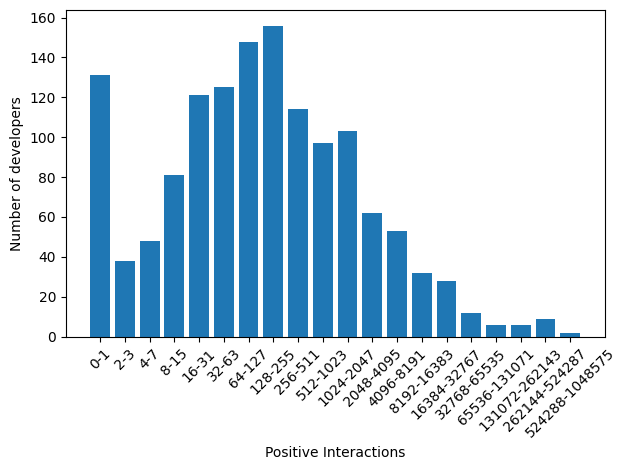

In [43]:
dev_game_four = result[result["count"] == 4]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_four["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_four["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

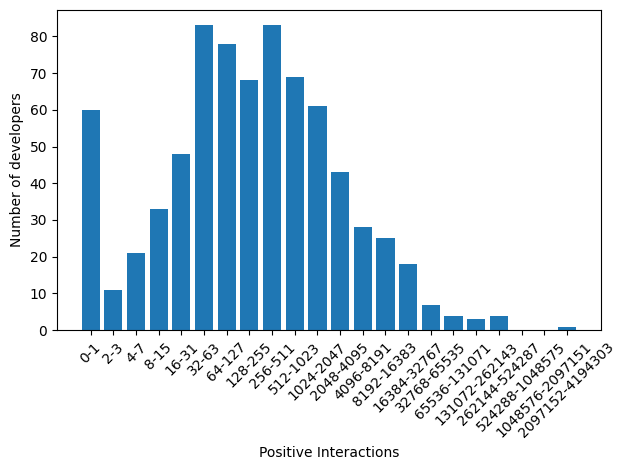

In [44]:
dev_game_five = result[result["count"] == 5]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_five["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_five["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

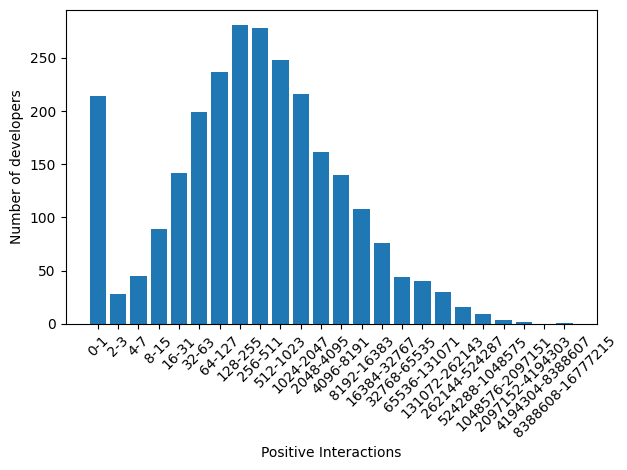

In [45]:
dev_game_over_5 = result[result["count"] >= 5]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_over_5["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_over_5["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

We analyzed the relationship between the success of a video game developer and the number of games released by that developer. We used number of "Positives" (similar to "likes" or "up votes" on other platforms) as a proxy for success. We visualized developers as a whole by graphing developer count as a function of number of games released. As expected there was a logarithmic decay, with most developers releasing only one game and fewer developers releasing further games at each increment.

We then visualized developers by level of success. We saw a large spike in the number of developers with essentially no success, followed by a small increase in developer count at low levels of success, and then a rapid decline in developer count at moderate or higher levels of success.

We then broke the developers into classes based on the number of games released and performed the same visualization. The data shows the same large spike of developers with no success. Aside from this peak, however, there is another peak representing the middle point of the distribution. We observe that this point moves forward (toward more success) the more games released by a class of developers. We also observe that the peak, as well as the basic range of success, remain relatively stable after 4 games released.